# Web bot traffic detection: walkthrough
Runs the pipeline in `src/` and shows each stage. **The bot sessions are synthetic and were injected by `src/inject_bots.py`.**

In [1]:
import os, sys, json
os.chdir('..'); sys.path.insert(0, 'src')
import pandas as pd
from IPython.display import Image, Markdown, display
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 30)

## 1. Parse the real log

In [2]:
from parse_logs import parse_file
real = parse_file('data/access.log')
print(len(real), 'lines parsed,', real.attrs['unparsed_lines'], 'unparsed')
real.head()

10000 lines parsed, 0 unparsed


,ip,method,url,status,bytes,referrer,user_agent,timestamp
0,83.149.9.216,GET,/presentations/logstash-monitorama-2013/images...,200,25230,http://semicomplete.com/presentations/logstash...,Mozilla/5.0 (Macintosh; Intel Mac OS X 10_9_1)...,2015-05-17 10:05:00+00:00
1,66.249.73.185,GET,/reset.css,200,1015,-,Mozilla/5.0 (compatible; Googlebot/2.1; +http:...,2015-05-17 10:05:00+00:00
2,83.149.9.216,GET,/presentations/logstash-monitorama-2013/images...,200,203023,http://semicomplete.com/presentations/logstash...,Mozilla/5.0 (Macintosh; Intel Mac OS X 10_9_1)...,2015-05-17 10:05:03+00:00
3,46.105.14.53,GET,/blog/tags/puppet?flav=rss20,200,14872,-,UniversalFeedParser/4.2-pre-314-svn +http://fe...,2015-05-17 10:05:03+00:00
4,110.136.166.128,GET,/style2.css,200,4877,http://www.semicomplete.com/projects/xdotool/,Mozilla/5.0 (Windows NT 6.2; WOW64; rv:28.0) G...,2015-05-17 10:05:03+00:00


## 2. Inject synthetic bots, sessionise, build features

In [3]:
from features import sessionize, build_features, FEATURES
dev = parse_file('data/access_with_bots.log'); labels = pd.read_csv('data/injected_labels.csv')
f = build_features(sessionize(dev), labels)
print(len(dev)-len(real), 'injected lines;', len(f), 'sessions;', int(f.is_injected.sum()), 'injected bot sessions')
f.groupby('bot_type')[FEATURES].median().round(2).T

5804 injected lines; 3092 sessions; 40 injected bot sessions


bot_type,empty_ua,fast_scraper,human_or_real,login_bruteforce,url_scanner
req_per_min,17.15,135.57,1.0,54.38,50.50
n_requests,72.00,284.50,1.0,194.00,50.50
distinct_urls,65.00,181.50,1.0,1.00,50.50
err_share,0.15,0.00,0.0,0.97,0.94
mean_gap,3.55,0.44,1800.0,1.11,1.10
var_gap,2.00,0.25,0.0,0.55,0.49
top_url_share,0.03,0.01,1.0,1.00,0.02
ua_browser,0.00,1.00,1.0,0.00,0.00
has_image,0.00,0.00,0.0,0.00,0.00
has_css,0.00,0.00,0.0,0.00,0.00


## 3. Run clustering, Isolation Forest, rules and evasion tests (`src/run_pipeline.py`)

In [4]:
%run src/run_pipeline.py

real parsed 10000 (unparsed 0); with bots 15804


{'log_lines_real': 10000, 'log_lines_injected': 5804, 'sessions_total': 3092, 'sessions_injected': 40, 'sessions_real': 3052, 'real_sessions_with_declared_bot_ua': 1072}


## Main results

| method                                        |   flagged |   TP |   FP |   FN |   precision |   recall |    F1 |   FP_declared_bot_ua |   FP_other |
|:----------------------------------------------|----------:|-----:|-----:|-----:|------------:|---------:|------:|---------------------:|-----------:|
| k-means k=15 (best silhouette)                |        42 |   40 |    2 |    0 |       0.952 |      1   | 0.976 |                    2 |          0 |
| DBSCAN noise only (eps=0.38, q=0.9)           |       243 |   16 |  227 |   24 |       0.066 |      0.4 | 0.113 |                   68 |        159 |
| DBSCAN noise + bot clusters (eps=0.38, q=0.9) |       267 |   40 |  227 |    0 |       0.15  |      1   | 0.261 |                   68 |        159 |
| Isolation Forest contamination=0.03           |        93 |   40 |   53 |    0 |       0.43  |      1   | 0.602 |                    3 |         50 |
| Rules R1-R3 (dev bots, seed 42)               |        41 |   40 |   

## 4. Results

In [5]:
pd.read_csv('results/results_table.csv')

,method,flagged,TP,FP,FN,precision,recall,F1,FP_declared_bot_ua,FP_other
0,k-means k=15 (best silhouette),42,40,2,0,0.952,1.0,0.976,2,0
1,"DBSCAN noise only (eps=0.38, q=0.9)",243,16,227,24,0.066,0.4,0.113,68,159
2,"DBSCAN noise + bot clusters (eps=0.38, q=0.9)",267,40,227,0,0.150,1.0,0.261,68,159
3,Isolation Forest contamination=0.03,93,40,53,0,0.430,1.0,0.602,3,50
4,"Rules R1-R3 (dev bots, seed 42)",41,40,1,0,0.976,1.0,0.988,1,0
5,"Rules R1-R3 (NEW bots, seed 7)",41,40,1,0,0.976,1.0,0.988,1,0


In [6]:
pd.read_csv('results/recall_by_bot_type.csv')

,bot type,k-means,DBSCAN noise,DBSCAN noise+bot clusters,Isolation Forest 3%,Rules R1-R3
0,empty_ua,1.0,1.0,1.0,1.0,1.0
1,fast_scraper,1.0,0.4,1.0,1.0,1.0
2,login_bruteforce,1.0,0.2,1.0,1.0,1.0
3,url_scanner,1.0,0.0,1.0,1.0,1.0


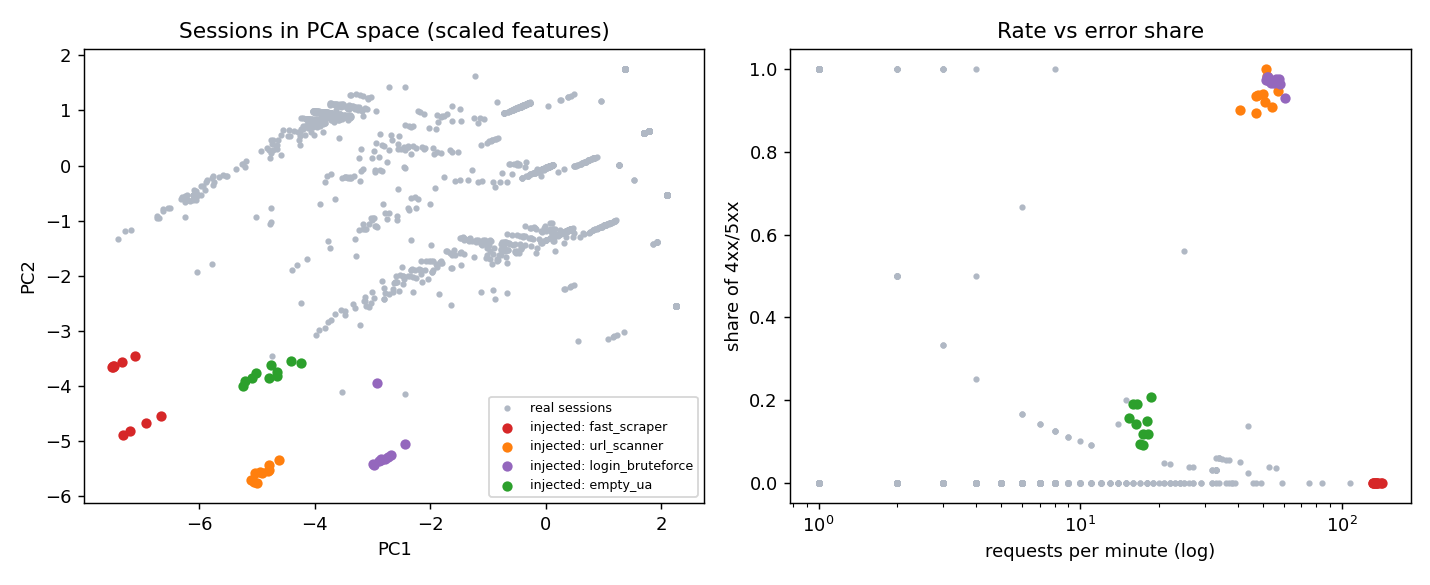

In [7]:
display(Image('results/fig_sessions.png'))

### Evasion

In [8]:
pd.read_csv('results/evasion.csv')

,evasion level,caught by rules (IPs),caught by IForest (IPs),guesses/hour/IP,days for 10k guesses (1 IP),IPs needed for 10k in 24 h
0,"E0 baseline (1 s, python UA)",20/20,20/20,3474.2,0.1,1
1,E1 + browser UA & fetch CSS/img,20/20,20/20,3334.7,0.1,1
2,"E2 + slow, jittered (mean 5 s)",20/20,20/20,713.6,0.6,1
3,E3 + slower (mean 30 s),20/20,20/20,119.7,3.5,4
4,E4 + pad 3 benign GETs per guess (8 s),0/20,20/20,111.9,3.7,4
5,"E5 burst of 10, sleep 31 min",0/20,20/20,25.3,16.4,17
6,"E6 burst of 6 + 2 benign GETs each, sleep 31 min",0/20,20/20,14.8,28.1,29


### Incident summary

In [9]:
display(Markdown(open('results/incident.md').read()))

**Synthetic incident (injected, not real traffic): credential-stuffing burst against /login**

- **Source:** 203.0.113.242 (documentation range, synthetic), UA `python-requests/2.2.1 CPython/2.7.6`
- **Window:** 2015-05-19 09:50:31–09:55:47 UTC (316 s)
- **Volume:** 279 `POST /login` requests, ~53/min, 97% answered 401, 8 succeeded (302)
- **Footprint:** a single URL (`distinct_urls = 1`), no CSS/images, no referrer
- **Detection:** Isolation Forest anomaly score rank 10 of 3092; flagged by IForest, k-means bot cluster, rule R2 (error storm) and R1.
- **Time to rule trigger:** R2 fires at request 15, 16 s after the first request, i.e. after 14 free guesses.
- **Impact if unblocked:** 8 guesses got a non-401 answer; each is a potentially valid credential and must be treated as a compromised-account candidate until verified.
- **Recommended response:** block/rate-limit the IP at the edge, force password reset for any account that returned 302 to this IP, and add per-account failed-login throttling.
